In [2]:
import tensorflow as tf
from tensorflow import keras #Sequential and functional API
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist, fashion_mnist
import numpy as np
import matplotlib.pyplot as plt

The MNIST (Modified National Institute of Standards and Technology) database is a foundational dataset of 70,000 grayscale, 28x28 pixel images of handwritten digits (0-9) used for training and testing image processing and machine learning models. It includes 60,000 training and 10,000 testing images,

In [3]:
(x_train,y_train), (x_test,y_test) = mnist.load_data()
# (x_train,y_train), (x_test,y_test) = fashion_mnist.load_data()
print(x_train.shape)
print(y_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
(60000, 28, 28)
(60000,)


In [4]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

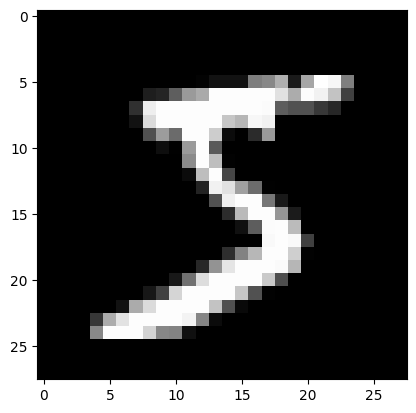

In [5]:
plt.imshow(x_train[0].reshape((28,28)),cmap = 'gray')

In [6]:
x_train = x_train.reshape(-1,28*28).astype("float32")/255.0
x_test = x_test.reshape(-1,784).astype("float32")/255.0

print(x_train.shape)

(60000, 784)


In [8]:
# Functional API (A bit more flexible)
inputs = keras.Input(shape = (784,))
x = layers.Dense(64,activation='relu',name = 'first_layer')(inputs)
x = layers.Dense(32,activation='relu',name = 'second_layer')(x)
#x = layers.Dense(16,activation='relu',name = 'third_layer')(x)
outputs = layers.Dense(20,activation ='softmax')(x)

model = keras.Model(inputs = inputs, outputs = outputs)

print(model.summary())

model.compile(
    loss = keras.losses.SparseCategoricalCrossentropy(),
    optimizer = keras.optimizers.Adam(learning_rate = 0.001),
    metrics = ["accuracy"]
)
model.fit(x_train,y_train,batch_size=64,epochs=10)
model.evaluate(x_test,y_test,batch_size = 64)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ first_layer (Dense)                  │ (None, 64)                  │          50,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ second_layer (Dense)                 │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 20)                  │             660 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 52,980 (206.95 KB)

 Trainable params: 52,980 (206.95 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8978 - loss: 0.3628
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9549 - loss: 0.1564
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9647 - loss: 0.1188
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9711 - loss: 0.0956
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9754 - loss: 0.0817
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9778 - loss: 0.0701
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9807 - loss: 0.0606
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9836 - loss: 0.0533
Epoch 9/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9854 - loss: 0.0465
Epoch 10/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9874 - loss: 0.0416
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9711 - loss: 0.1047


[0.10470002144575119, 0.9710999727249146]

In [9]:
np.argmax(model.predict(np.array([x_train[0]])))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


np.int64(5)

In [10]:
ypred = np.argmax(model.predict(x_test),axis = 1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 704us/step


In [11]:
np.mean(ypred == y_test)

np.float64(0.9711)

In [12]:
ypred[0]

np.int64(7)

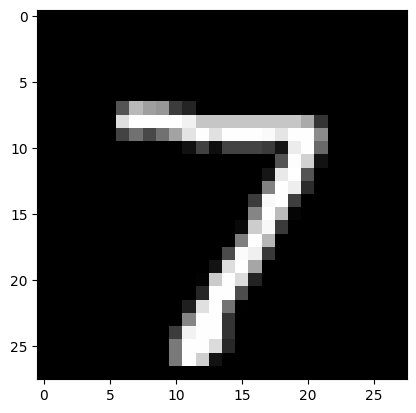

In [13]:
plt.imshow(x_test[0].reshape((28,28)),cmap = 'gray')

In [42]:
import cv2
import numpy as np

img = cv2.imread("digit.jpg")    
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

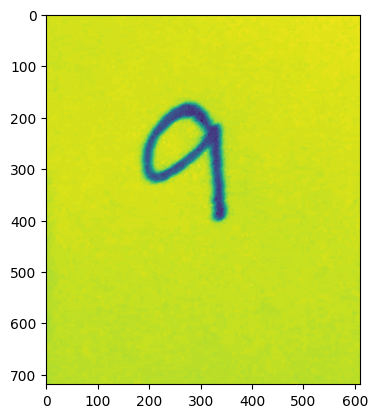

In [44]:
plt.imshow(img)

In [45]:
#blur = cv2.GaussianBlur(gray, (5, 5), 0) #Reduce noise
# thresh = cv2.adaptiveThreshold(
#     blur,
#     255,
#     cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
#     cv2.THRESH_BINARY_INV,  # invert: digit becomes white
#     11,
#     2
# )  #white number on black background 
#OR 
img = cv2.GaussianBlur(img, (5,5), 0)

_, img = cv2.threshold(
    img, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

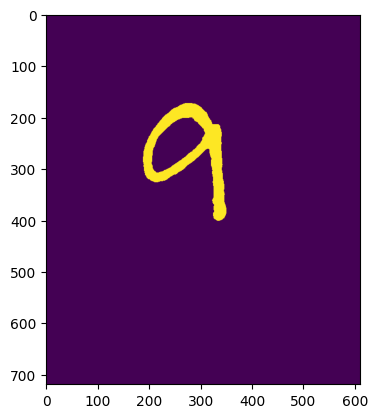

In [46]:
plt.imshow(img)

In [47]:
ys, xs = np.where(img > 0)
img = img[min(ys):max(ys), min(xs):max(xs)]

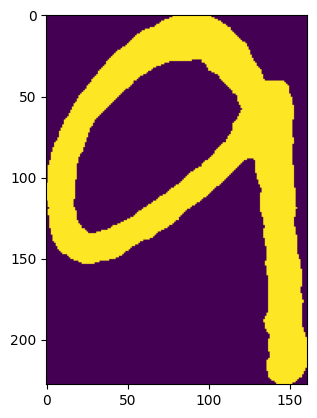

In [48]:
plt.imshow(img)

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

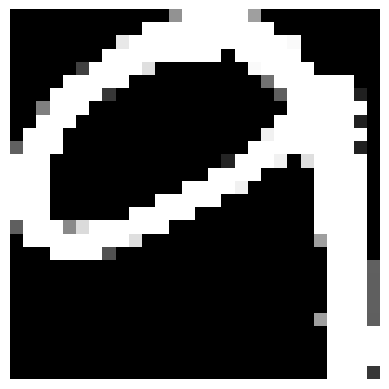

In [49]:
img = cv2.resize(img, (28, 28))

plt.imshow(img, cmap="gray")
plt.axis("off")

In [50]:
img = img.reshape(1, 28*28)

In [51]:
pred = model.predict(img)
digit = np.argmax(pred, axis=1)[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


In [52]:
print("Predicted digit:", digit)

Predicted digit: 9


In [14]:
#(x_train,y_train), (x_test,y_test) = mnist.load_data()
(x_train,y_train), (x_test,y_test) = fashion_mnist.load_data()
print(x_train.shape)
print(y_train.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28)
(60000,)


In [ ]:
np.unique(y_train)

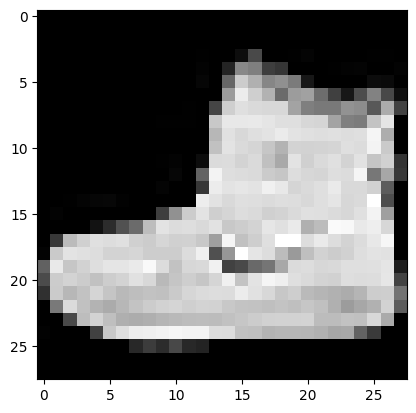

In [15]:
plt.imshow(x_train[0].reshape((28,28)),cmap = 'gray')

In [16]:
x_train = x_train.reshape(-1,28*28).astype("float32")/255.0
x_test = x_test.reshape(-1,784).astype("float32")/255.0

print(x_train.shape)

(60000, 784)


In [17]:
# Functional API (A bit more flexible)
inputs = keras.Input(shape = (784,))
x = layers.Dense(64,activation='relu',name = 'first_layer')(inputs)
x = layers.Dense(32,activation='relu',name = 'second_layer')(x)
#x = layers.Dense(16,activation='relu',name = 'third_layer')(x)
outputs = layers.Dense(20,activation ='softmax')(x)

model = keras.Model(inputs = inputs, outputs = outputs)

print(model.summary())

model.compile(
    loss = keras.losses.SparseCategoricalCrossentropy(),
    optimizer = keras.optimizers.Adam(learning_rate = 0.001),
    metrics = ["accuracy"]
)
model.fit(x_train,y_train,batch_size=64,epochs=10)
model.evaluate(x_test,y_test,batch_size = 64)

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ first_layer (Dense)                  │ (None, 64)                  │          50,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ second_layer (Dense)                 │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 20)                  │             660 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 52,980 (206.95 KB)

 Trainable params: 52,980 (206.95 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8021 - loss: 0.5786
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8568 - loss: 0.4032
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8684 - loss: 0.3652
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8762 - loss: 0.3384
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8843 - loss: 0.3196
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8870 - loss: 0.3056
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8928 - loss: 0.2925
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8950 - loss: 0.2852
Epoch 9/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8992 - loss: 0.2735
Epoch 10/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9018 - loss: 0.2651
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8772 - loss: 0.3442  


[0.3442141115665436, 0.8772000074386597]

In [18]:
np.argmax(model.predict(np.array([x_train[0]])))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


np.int64(9)

In [19]:
ypred = np.argmax(model.predict(x_test),axis = 1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 919us/step


In [20]:
np.mean(ypred == y_test)

np.float64(0.8772)

In [21]:
ypred[0]

np.int64(9)

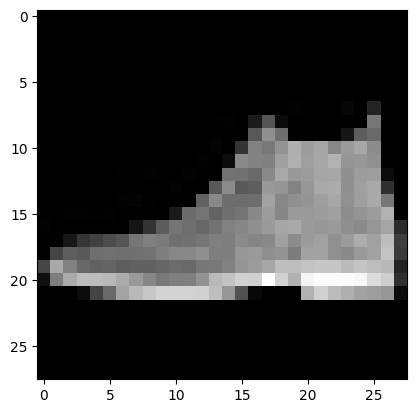

In [22]:
plt.imshow(x_test[0].reshape((28,28)),cmap = 'gray')